# Plot colours

PyTES has its own plot colours (DESIGN D15), chosen to stay readable with colour-vision
deficiency and led by the brand orange:

- the colour cycles **PyTES Thermal**, for light backgrounds, and **PyTES Thermal (dark)**,
  for dark ones, as the matplotlib styles `"pytes.thermal"` and `"pytes.thermal_dark"`;
- the colourmaps **ember** (sequential) and **thaw** (diverging), perceptually uniform,
  registered with matplotlib as `"pytes.ember"` and `"pytes.thaw"` (and reversed, ending
  in `_r`) when `pytes.plotting` is imported.

They are available but not yet the default: matplotlib's own colours apply until you ask for
these. This notebook shows each of them on a packed bed charge.

[Tutorial 5](getting_started/tutorial_5_plotting.ipynb) introduces plotting PyTES solutions.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pybamm
from matplotlib.colors import CenteredNorm

import pytes
from pytes import plotting

model = pytes.PackedBedModel()
solution = pybamm.Simulation(model).solve([0, 1800])

## Colour cycles

Use a cycle for one figure with `plt.style.context`, or for every figure with
`plt.style.use("pytes.thermal")`. Seven fluid temperature profiles, every 2.5 minutes as the charge front crosses the
bed, use all seven colours in order:

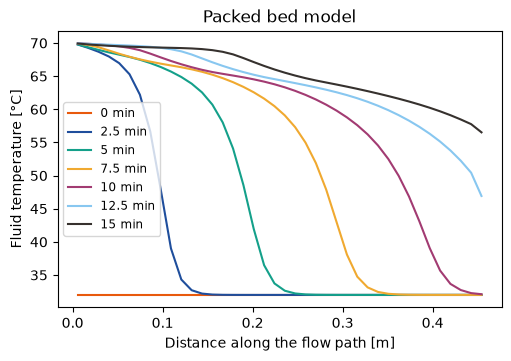

In [2]:
times = np.linspace(0, 900, 7)
with plt.style.context("pytes.thermal"):
    plotting.plot_fluid_profiles(solution, times)
    plt.show()

For dark backgrounds, combine a dark style with PyTES Thermal (dark), which comes second so
that its colours win:

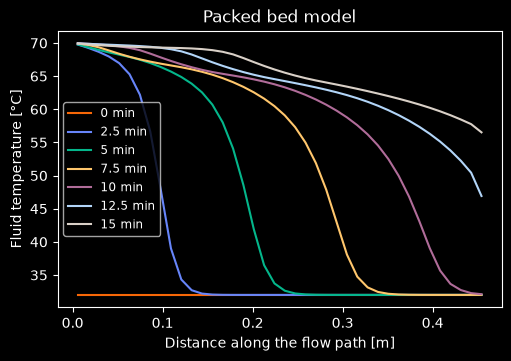

In [3]:
with plt.style.context(["dark_background", "pytes.thermal_dark"]):
    plotting.plot_fluid_profiles(solution, times)
    plt.show()

The colours are also `plotting.THERMAL` and `plotting.THERMAL_DARK`. A style does not reach
`pybamm.QuickPlot` (and so `Simulation.plot`) until PyBaMM uses matplotlib's colour cycle
there (pybamm-team/PyBaMM#5953); meanwhile, pass the colours to it:
`pybamm.QuickPlot(solution, colors=list(plotting.THERMAL))`.

## Colourmaps

Ember runs from dark brown through the brand orange to cream, with lightness rising steadily
and equal perceptual steps, so it suits a field such as the fluid temperature along the bed
over time:

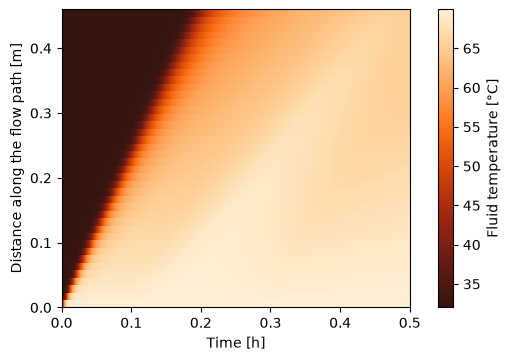

In [4]:
fluid = solution["Heat transfer fluid temperature [degC]"]
z = fluid.mesh.nodes
t = solution["Time [h]"].entries
T = fluid(t=solution.t, z=z)

fig, ax = plt.subplots(figsize=(5, 3.5), layout="constrained")
field = ax.pcolormesh(t, z, T, cmap="pytes.ember", shading="nearest")
fig.colorbar(field, label="Fluid temperature [°C]")
ax.set_xlabel("Time [h]")
ax.set_ylabel("Distance along the flow path [m]")
plt.show()

Thaw is diverging, from blue through a pale centre to orange. Centre it on a reference value
with matplotlib's `CenteredNorm`, here the PCM melting temperature: the pale band is the
fluid at the melting temperature, orange above it and blue below. `CenteredNorm` makes the
range symmetric about the centre, so a kelvin is the same step in colour on both sides,
and the orange side stops short of its darkest red because the fluid never gets 28 K above
the melting temperature. (`TwoSlopeNorm` would stretch each half over its own range, here
28 K below the centre and 10 K above, so that a kelvin would look 2.8 times bigger above
it. It suits two sides that are not comparable, such as different units.)

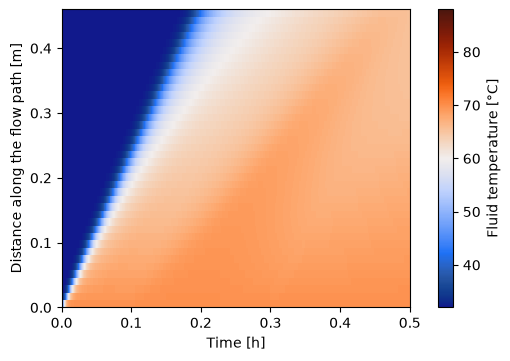

In [5]:
T_melt = model.default_parameter_values["PCM melting temperature [K]"] - 273.15
norm = CenteredNorm(vcenter=T_melt)

fig, ax = plt.subplots(figsize=(5, 3.5), layout="constrained")
field = ax.pcolormesh(t, z, T, cmap="pytes.thaw", norm=norm, shading="nearest")
fig.colorbar(field, label="Fluid temperature [°C]")
ax.set_xlabel("Time [h]")
ax.set_ylabel("Distance along the flow path [m]")
plt.show()